# Модель оценки риска выдачи кредита



In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, average_precision_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Чтение датасета
df = pd.read_csv("cs-training.csv")

# Вывод информации о датасете
print(f"Размер датасета: {df.shape[0]:,} строк × {df.shape[1]} столбцов")
df.info()
df.head()

Размер датасета: 150,000 строк × 12 столбцов
<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 12 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   Unnamed: 0                            150000 non-null  int64  
 1   SeriousDlqin2yrs                      150000 non-null  int64  
 2   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 3   age                                   150000 non-null  int64  
 4   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 5   DebtRatio                             150000 non-null  float64
 6   MonthlyIncome                         120269 non-null  float64
 7   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 8   NumberOfTimes90DaysLate               150000 non-null  int64  
 9   NumberRealEstateLoansOrLines          150000 non-null  int64  
 10  NumberOfTime60-89DaysPastDueNotWor

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


# Проверка на наличие пропусков

In [42]:
df[df.isnull().any(axis=1)] # Проверка на наличие пропусков

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
6,7,0,0.305682,57,0,5710.0,NaN,8,0,3,0,0.0
8,9,0,0.116951,27,0,46.0,NaN,2,0,0,0,NaN
16,17,0,0.061086,78,0,2058.0,NaN,10,0,2,0,0.0
32,33,0,0.083418,62,0,977.0,NaN,6,0,1,0,0.0
41,42,0,0.072898,81,0,75.0,NaN,7,0,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
149976,149977,0,0.000627,76,0,60.0,NaN,5,0,0,0,0.0
149977,149978,0,0.236450,29,0,349.0,NaN,3,0,0,0,0.0
149984,149985,0,0.037548,84,0,25.0,NaN,5,0,0,0,0.0
149992,149993,0,0.871976,50,0,4132.0,NaN,11,0,1,0,3.0


Строки с пропусками сохраняем. После разбиения заполним пропуски медианами обучающей выборки и добавим индикаторы отсутствующих значений.

In [43]:
df = df.drop(columns=["Unnamed: 0"]) # Удаление служебного индекса
print(f"Размер датасета: {df.shape[0]:,} строк × {df.shape[1]} столбцов")
print("Пропуски до заполнения:")
print(df.isna().sum())

Размер датасета: 150,000 строк × 11 столбцов
Пропуски до заполнения:
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64


Все 150 000 строк сохранены. Стратификация сохраняет долю целевого класса в train и test; тест не используется для обучения преобразований или подбора параметров.

In [44]:
X = df.drop('SeriousDlqin2yrs', axis=1)
y = df['SeriousDlqin2yrs']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Доля класса 1: train={y_train.mean():.2%}, test={y_test.mean():.2%}")

Доля класса 1: train=6.68%, test=6.68%


Заполнение пропусков и масштабирование обучаем только на train. Индикаторы пропусков позволяют модели учитывать отсутствие данных.

In [45]:
imputer = SimpleImputer(strategy="median", add_indicator=True)
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Среднее train после масштабирования:", X_train_scaled.mean(axis=0).round(2))
print("Стандартное отклонение train:", X_train_scaled.std(axis=0).round(2))
assert np.isfinite(X_train_scaled).all()
assert np.isfinite(X_test_scaled).all()

Среднее train после масштабирования: [-0.  0.  0.  0.  0.  0. -0. -0.  0.  0.  0. -0.]
Стандартное отклонение train: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


На следующем шаге можно приступать к обучению модели.

In [46]:
# Веса классов увеличивают штраф за ошибки на редком классе 1.
# Фиксируем параметры заранее; порог на тестовой выборке не подбираем.
model = LogisticRegression(random_state=42, max_iter=1000, class_weight="balanced")
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

Оцениваем Average Precision, ROC-AUC и метрики класса 1. Веса классов могут повысить recall ценой precision. Выход predict_proba после взвешивания нельзя автоматически считать откалиброванной вероятностью просрочки.

In [47]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]

threshold = 0.5
y_pred = (y_prob >= threshold).astype(int)

# Оцениваем логистическую регрессию
print("Logistic Regression:")
print(f"- Average Precision: {average_precision_score(y_test, y_prob):.4f}")
print(f"- ROC-AUC:           {roc_auc_score(y_test, y_prob):.4f}")
print(f"- Precision (1):     {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"- Recall (1):        {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"- F1-score (1):      {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"- Accuracy:          {accuracy_score(y_test, y_pred):.4f}")

Logistic Regression:
- Average Precision: 0.3229
- ROC-AUC:           0.8019
- Precision (1):     0.1815
- Recall (1):        0.6708
- F1-score (1):      0.2857
- Accuracy:          0.7758


Теперь можно посмотреть на матрицу ошибок

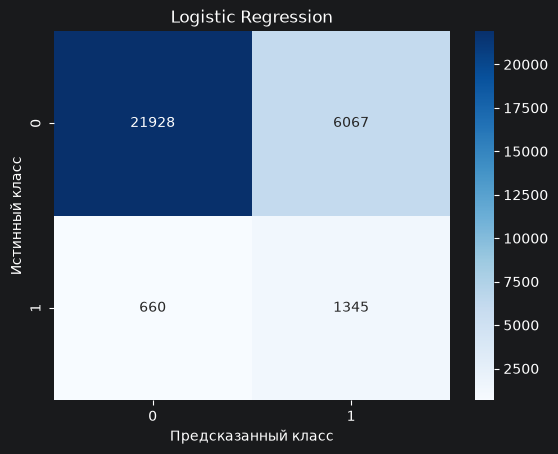

In [48]:
log_cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots()
sns.heatmap(log_cm, annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set_title("Logistic Regression")
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
plt.show()

## Сравнение с градиентным бустингом
Обучаем бустинг на том же train, что и логистическую регрессию выше, и сравниваем метрики на одном test. Бустинг обрабатывает пропуски напрямую и не требует масштабирования. Для обеих моделей используем стандартный порог 0.5, без подбора на тесте.

In [52]:
from sklearn.ensemble import HistGradientBoostingClassifier

gb_model = HistGradientBoostingClassifier(
    learning_rate=0.05, max_iter=250, max_leaf_nodes=15,
    min_samples_leaf=40, l2_regularization=10.0, random_state=42,
)
gb_model.fit(X_train, y_train)

y_prob_gb = gb_model.predict_proba(X_test)[:, 1]
y_pred_gb = gb_model.predict(X_test)

In [53]:
# Сравниваем бустинг с уже обученной логистической регрессией
y_prob_lr = model.predict_proba(X_test_scaled)[:, 1]
y_pred_lr = model.predict(X_test_scaled)

results = []
for name, prob, pred in [
    ("Logistic Regression", y_prob_lr, y_pred_lr),
    ("Gradient Boosting", y_prob_gb, y_pred_gb),
]:
    results.append({
        "Модель": name,
        "Average Precision": average_precision_score(y_test, prob),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "Accuracy": accuracy_score(y_test, pred),
    })
pd.DataFrame(results).set_index("Модель").round(4)

,Average Precision,ROC-AUC,Precision,Recall,F1,Accuracy
Модель,,,,,,
Logistic Regression,0.3229,0.8019,0.1815,0.6708,0.2857,0.7758
Gradient Boosting,0.4081,0.8688,0.6059,0.1840,0.2823,0.9375


### Матрица ошибок градиентного бустинга

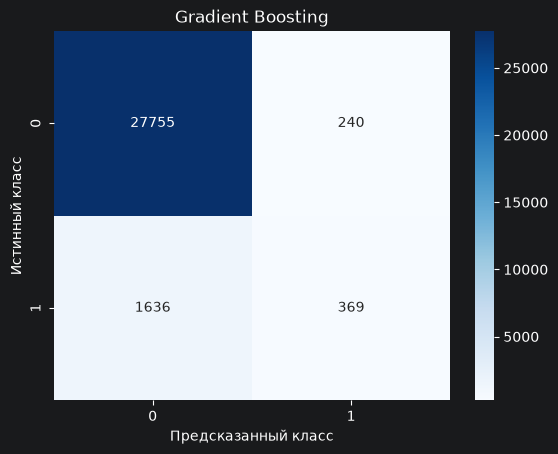

In [54]:
fig, ax = plt.subplots()
sns.heatmap(confusion_matrix(y_test, y_pred_gb), annot=True, fmt='d', cmap='Blues', ax=ax)
ax.set_title("Gradient Boosting")
ax.set_xlabel("Предсказанный класс")
ax.set_ylabel("Истинный класс")
plt.show()

## Итоговое сравнение

При